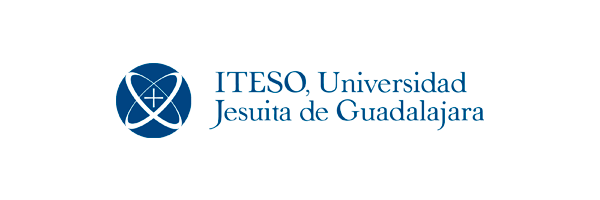

# Proyecto 2. Práctica de Redes Neuronales Estáticas

## Predicción del riesgo de quiebra de empresas

**Integrantes:**

- Valeria Esmer Lobo

- Dayanni Godoy Rosales

- Estephany Lisset Herrera Placencia

- Maria Fernanda Vargas Vaca

**Fecha:** 12 de noviembre de 2026

**Institución:** Instituto Tecnológico y de Estudios Superiores de Occidente (ITESO)

**Departamento:** Matemáticas y Física

**Materia:** Métodos de Inteligencia Artificial

## Índice

1. [Introducción](#introduccion)
2. [Objetivos](#objetivos)
3. [Base de datos](#base-datos)
4. [Tratamiento previo y normalización](#tratamiento)
    - 4.1 [¿Qué es la normalización y para qué sirve?](#que-es-normalizacion)
    - 4.2 [Método utilizado](#metodo)
    - 4.3 [Implementación](#implementacion-tratamiento)
    - 4.4 [Resultados del tratamiento](#resultados-tratamiento)
5. [Archivos de datos tratados](#archivos)

<a id="introduccion"></a>

## 1. Introducción

Predecir si una empresa puede caer en **quiebra** (*default*) es una de las aplicaciones más importantes de la clasificación en finanzas. Bancos, inversionistas y reguladores necesitan identificar a tiempo a las empresas en riesgo, y para eso cuentan con sus **razones financieras**: rentabilidad, liquidez, endeudamiento, rotación de activos, entre otras.

Existen dos formas de abordar el problema:

- **Clasificación no supervisada:** se agrupan las empresas solo por la similitud de sus razones financieras, sin saber cuáles quebraron. En este proyecto se hace con una **red competitiva**, donde cada neurona representa un grupo de empresas con características parecidas.
- **Clasificación supervisada:** se entrena un modelo con la etiqueta real de quiebra para aprender una regla que clasifique empresas nuevas. Para esto se usa una red **ADALINE** o **perceptrón**.

Antes de entrenar cualquier red hay que **tratar los datos**. Las razones financieras vienen en escalas muy distintas y algunas traen valores extremos que, si no se corrigen, dominan el entrenamiento y empeoran los resultados. Por eso, este documento comienza con la obtención de la base de datos y su tratamiento previo, que sirven de base para los modelos de las siguientes secciones.

<a id="objetivos"></a>

## 2. Objetivos

**Objetivo general:** construir clasificadores basados en redes neuronales estáticas (supervisados y no supervisados) que permitan identificar si una empresa tiene riesgo de irse a la quiebra a partir de sus razones financieras.

**Objetivos específicos**

1. Obtener una base de datos pública de empresas con al menos 500 registros y 10 razones financieras, y preparar los datos con un tratamiento previo y una normalización adecuados.
2. Seleccionar las variables que más influyen en la quiebra y justificar la selección.
3. Agrupar las empresas con una **red competitiva** y analizar cómo se distribuyen las empresas en quiebra dentro de cada grupo.
4. Entrenar una red **ADALINE o perceptrón** con la etiqueta real de quiebra y medir su desempeño (exactitud, precisión y *recall*).
5. Usar los dos mejores modelos para predecir si 5 empresas nuevas, no vistas en el entrenamiento, tienen riesgo de quiebra.

<a id="base-datos"></a>

## 3. Base de datos

| Característica | Detalle |
|---|---|
| Nombre | *Taiwanese Bankruptcy Prediction* |
| Fuente | UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/572/taiwanese+bankruptcy+prediction |
| Origen de los datos | *Taiwan Economic Journal*, empresas de Taiwán de 1999 a 2009 |
| Registros | 6 819 empresas (requisito: al menos 500) |
| Variables | 95 razones financieras (requisito: al menos 10) |
| Etiqueta | `Bankrupt?` → 1 = quiebra, 0 = sana. Una empresa se considera en quiebra según las reglas de la Bolsa de Taiwán |

**¿Por qué esta base?** Es pública, es de las más usadas en la literatura de predicción de quiebra, supera por mucho los requisitos de tamaño y trae la etiqueta real de quiebra, que se necesita para el modelo supervisado y para revisar los grupos de la red competitiva.

Las variables cubren las principales familias de razones financieras: **rentabilidad** (ROA, márgenes, utilidad por acción), **liquidez** (razón circulante, prueba ácida, efectivo / pasivo circulante), **endeudamiento** (deuda / capital, dependencia de préstamos), **actividad** (rotación de inventarios, de cuentas por cobrar, de activos) y **crecimiento** (crecimiento de activos, de capital, de utilidades).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Rutas del repositorio (el notebook está en la carpeta raíz)
ruta_cruda = Path("datos/crudos/taiwan_bankruptcy.csv")
carpeta_tratados = Path("datos/tratados")
carpeta_img = Path("img")
carpeta_tratados.mkdir(parents=True, exist_ok=True)
carpeta_img.mkdir(parents=True, exist_ok=True)

semilla = 42             # Semilla fija: todo el equipo obtiene la misma división
col_objetivo = "quiebra"

# Lectura y limpieza de nombres de columnas
datos = pd.read_csv(ruta_cruda)
datos.columns = datos.columns.str.strip()                    # Quitar espacios sobrantes
datos = datos.rename(columns={"Bankrupt?": col_objetivo})    # 1 = quiebra, 0 = sana

print(f"Empresas: {datos.shape[0]} | Variables: {datos.shape[1] - 1}")
datos.head()

Empresas: 6819 | Variables: 95


,quiebra,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


In [2]:
# Revisión de calidad de los datos
faltantes = int(datos.isna().sum().sum())
duplicados = int(datos.duplicated().sum())
constantes = [col for col in datos.columns if datos[col].nunique() <= 1]
binarias = [col for col in datos.columns if datos[col].nunique() == 2 and col != col_objetivo]

print(f"Datos faltantes: {faltantes}")
print(f"Filas duplicadas: {duplicados}")
print(f"Variables constantes (no aportan información): {constantes}")
print(f"Variables binarias (0/1): {binarias}")

conteo = datos[col_objetivo].value_counts().sort_index()
print(f"\nEmpresas sanas: {conteo[0]} | Empresas en quiebra: {conteo[1]} ({conteo[1] / len(datos):.2%})")

Datos faltantes: 0
Filas duplicadas: 0
Variables constantes (no aportan información): ['Net Income Flag']
Variables binarias (0/1): ['Liability-Assets Flag']

Empresas sanas: 6599 | Empresas en quiebra: 220 (3.23%)


In [3]:
# Variables con valores fuera de la escala 0-1 de la base
fuera_escala = (datos.drop(columns=col_objetivo) > 1).mean()
extremas = pd.DataFrame({"% de empresas con valor > 1": (fuera_escala * 100).round(2),
                         "Mediana": datos.drop(columns=col_objetivo).median(),
                         "Máximo": datos.drop(columns=col_objetivo).max()})
extremas = extremas[extremas["% de empresas con valor > 1"] > 0].sort_values("% de empresas con valor > 1")
print(f"Variables con valores mayores a 1: {len(extremas)} de {datos.shape[1] - 1}")
extremas.style.format({"% de empresas con valor > 1": "{:.2f}", "Mediana": "{:.4g}", "Máximo": "{:.3g}"})

Variables con valores mayores a 1: 24 de 95


,% de empresas con valor > 1,Mediana,Máximo
Current Ratio,0.01,0.01059,2.75e+09
Fixed Assets to Assets,0.01,0.1969,8.32e+09
Revenue per person,0.03,0.01862,8.81e+09
Net Value Growth Rate,0.03,0.000462,9.33e+09
Quick Assets/Current Liability,0.04,0.007909,8.82e+09
Revenue Per Share (Yuan ¥),0.07,0.02738,3.02e+09
Total debt/Total net worth,0.12,0.005546,9.94e+09
Quick Ratio,0.13,0.007412,9.23e+09
Allocation rate per person,0.18,0.007844,9.57e+09
Average Collection Days,0.26,0.006573,9.73e+09


**Hallazgos de la revisión**

- No hay datos faltantes ni empresas duplicadas.
- `Net Income Flag` vale 1 para todas las empresas, así que no distingue entre ellas y se elimina.
- `Liability-Assets Flag` es una variable binaria (0/1). Se conserva, pero no se recorta.
- La fuente entrega las razones financieras **ya escaladas entre 0 y 1**, pero **24 variables tienen valores de hasta $10^{10}$**. Estos valores no son consistentes con la escala de la base y hay que tratarlos. Hay dos casos (tabla siguiente):
    - En **16 variables** los valores mayores a 1 son pocos (menos del 5 % de las empresas). Se consideran errores de captura y se corrigen con la winsorización.
    - En **8 variables** entre el 18 % y el 88 % de las empresas tienen valores mayores a 1. La variable mezcla dos escalas distintas y no es confiable, así que se elimina.
- La base está **desbalanceada**: solo el 3.2 % de las empresas quebró. Esto se tiene que considerar al entrenar y evaluar los modelos, porque un modelo que diga "ninguna quiebra" ya tendría 96.8 % de exactitud.

<a id="tratamiento"></a>

## 4. Tratamiento previo y normalización

<a id="que-es-normalizacion"></a>

### 4.1 ¿Qué es la normalización y para qué sirve?

**Normalizar** es transformar los valores de cada variable para que todas queden en una escala comparable, sin cambiar la información que contienen. Sirve para:

- **Que ninguna variable domine por su tamaño.** En una red competitiva la neurona ganadora se elige por distancia euclidiana; si una variable va de 0 a $10^{10}$ y otra de 0 a 1, la distancia dependería casi solo de la primera.
- **Que el gradiente descendente converja.** En ADALINE y en el perceptrón, las variables con escalas muy distintas hacen que el gradiente "zigzaguee" o diverja; con todas en la misma escala la red aprende más rápido y es más estable.
- **Que los pesos se puedan comparar** entre variables.

Los métodos más comunes son:

| Método | Fórmula | Resultado |
|---|---|---|
| Min-Max | $x' = \dfrac{x - x_{min}}{x_{max} - x_{min}}$ | Valores entre 0 y 1 |
| Z-score (estandarización) | $z = \dfrac{x - \mu}{\sigma}$ | Media 0 y desviación estándar 1 |

<a id="metodo"></a>

### 4.2 Método utilizado

Se aplicó un tratamiento en **cuatro pasos**:

1. **División de los datos antes de tratarlos.**
   - Primero se apartan **5 empresas nuevas** (2 en quiebra y 3 sanas) que no se usan en ningún entrenamiento y sirven para la predicción final del proyecto.
   - El resto se divide en **entrenamiento (80 %)** y **prueba (20 %)** de forma **estratificada**, es decir, con la misma proporción de quiebras en ambos.
   - Todos los parámetros del tratamiento se calculan **solo con los datos de entrenamiento** y se aplican igual a prueba y a las empresas nuevas. Así los datos de prueba no "se filtran" al entrenamiento y la evaluación es honesta.
2. **Eliminación de variables con escala inconsistente.** Se eliminan las variables en las que más del 5 % de las empresas del entrenamiento tienen valores mayores a 1, junto con `Net Income Flag`, que es constante.
3. **Winsorización (recorte de valores extremos).** Cada variable continua se recorta a sus **percentiles 1 y 99**, calculados con los valores válidos (entre 0 y 1) del entrenamiento. Un valor por debajo del percentil 1 se reemplaza por ese percentil, y uno por arriba del percentil 99 (incluidos los errores de $10^{10}$), por el percentil 99. Así se corrigen los valores extremos sin borrar empresas. Las variables binarias no se recortan.
4. **Normalización Z-score:** $z = \dfrac{x - \mu}{\sigma}$, con la media $\mu$ y la desviación estándar $\sigma$ del entrenamiento.

**¿Por qué Z-score y no Min-Max?**
- Min-Max usa el mínimo y el máximo, que justo en esta base son valores extremos; con ellos casi todas las empresas quedarían aplastadas cerca de 0.
- Z-score centra cada variable en 0. Esto ayuda a que ADALINE y el perceptrón converjan más rápido con gradiente descendente y a que la sigmoide no se sature.
- Es el método que se usó en las prácticas del curso, así que los modelos de las siguientes secciones pueden trabajar directamente con estos datos.

<a id="implementacion-tratamiento"></a>

### 4.3 Implementación

In [4]:
# 1. Eliminar variables constantes
datos = datos.drop(columns=constantes)

# 2a. Apartar 5 empresas nuevas (2 en quiebra y 3 sanas) para la predicción final
rng = np.random.default_rng(semilla)
idx_quiebra = rng.choice(datos.index[datos[col_objetivo] == 1], size=2, replace=False)
idx_sanas = rng.choice(datos.index[datos[col_objetivo] == 0], size=3, replace=False)
idx_nuevas = np.concatenate([idx_quiebra, idx_sanas])
nuevas = datos.loc[idx_nuevas]
resto = datos.drop(index=idx_nuevas)

# 2b. Entrenamiento (80 %) y prueba (20 %) con la misma proporción de quiebras
entrenamiento, prueba = train_test_split(resto, test_size=0.20, random_state=semilla,
                                         stratify=resto[col_objetivo])

resumen_division = pd.DataFrame({
    "Empresas": [len(entrenamiento), len(prueba), len(nuevas)],
    "En quiebra": [int(entrenamiento[col_objetivo].sum()), int(prueba[col_objetivo].sum()), int(nuevas[col_objetivo].sum())]},
    index=["Entrenamiento", "Prueba", "Empresas nuevas"])
resumen_division["% quiebra"] = (resumen_division["En quiebra"] / resumen_division["Empresas"] * 100).round(2)
resumen_division

,Empresas,En quiebra,% quiebra
Entrenamiento,5451,174,3.19
Prueba,1363,44,3.23
Empresas nuevas,5,2,40.00


In [5]:
# 2. Eliminar variables con escala inconsistente (más del 5 % de valores > 1 en entrenamiento)
porcentaje_fuera = (entrenamiento.drop(columns=col_objetivo) > 1).mean()
inconsistentes = porcentaje_fuera[porcentaje_fuera > 0.05].index.tolist()
print("Variables eliminadas por escala inconsistente:")
for col in inconsistentes:
    print(f"  - {col} ({porcentaje_fuera[col]:.1%} de valores > 1)")

entrenamiento = entrenamiento.drop(columns=inconsistentes)
prueba = prueba.drop(columns=inconsistentes)
nuevas = nuevas.drop(columns=inconsistentes)
variables = [col for col in entrenamiento.columns if col != col_objetivo]
continuas = [col for col in variables if col not in binarias]
print(f"\nVariables a usar: {len(variables)} ({len(continuas)} continuas y {len(binarias)} binaria)")

# 3. Winsorización: percentiles 1 y 99 de los valores válidos (0 a 1) del entrenamiento
validos = entrenamiento[continuas].where(entrenamiento[continuas] <= 1)
p_inf = validos.quantile(0.01)
p_sup = validos.quantile(0.99)

def winsorizar(df):
    salida = df.copy()
    salida[continuas] = salida[continuas].clip(lower=p_inf, upper=p_sup, axis=1)
    return salida

entrenamiento_w = winsorizar(entrenamiento)
prueba_w = winsorizar(prueba)
nuevas_w = winsorizar(nuevas)

# 4. Normalización Z-score con la media y la desviación del entrenamiento
media = entrenamiento_w[variables].mean()
desviacion = entrenamiento_w[variables].std(ddof=0)

def normalizar(df):
    salida = df.copy()
    salida[variables] = (salida[variables] - media) / desviacion
    return salida

entrenamiento_z = normalizar(entrenamiento_w)
prueba_z = normalizar(prueba_w)
nuevas_z = normalizar(nuevas_w)

# Comprobación: en entrenamiento cada variable debe quedar con media 0 y desviación 1
print(f"Media máxima (en valor absoluto): {entrenamiento_z[variables].mean().abs().max():.2e}")
print(f"Desviación estándar: entre {entrenamiento_z[variables].std(ddof=0).min():.4f} y {entrenamiento_z[variables].std(ddof=0).max():.4f}")

Variables eliminadas por escala inconsistente:
  - Operating Expense Rate (33.5% de valores > 1)
  - Research and development expense rate (59.2% de valores > 1)
  - Total Asset Growth Rate (88.1% de valores > 1)
  - Inventory Turnover Rate (times) (43.3% de valores > 1)
  - Fixed Assets Turnover Frequency (18.1% de valores > 1)
  - Current Asset Turnover Rate (18.3% de valores > 1)
  - Quick Asset Turnover Rate (35.3% de valores > 1)
  - Cash Turnover Rate (62.8% de valores > 1)

Variables a usar: 86 (85 continuas y 1 binaria)


Media máxima (en valor absoluto): 7.61e-13
Desviación estándar: entre 1.0000 y 1.0000


<a id="resultados-tratamiento"></a>

### 4.4 Resultados del tratamiento

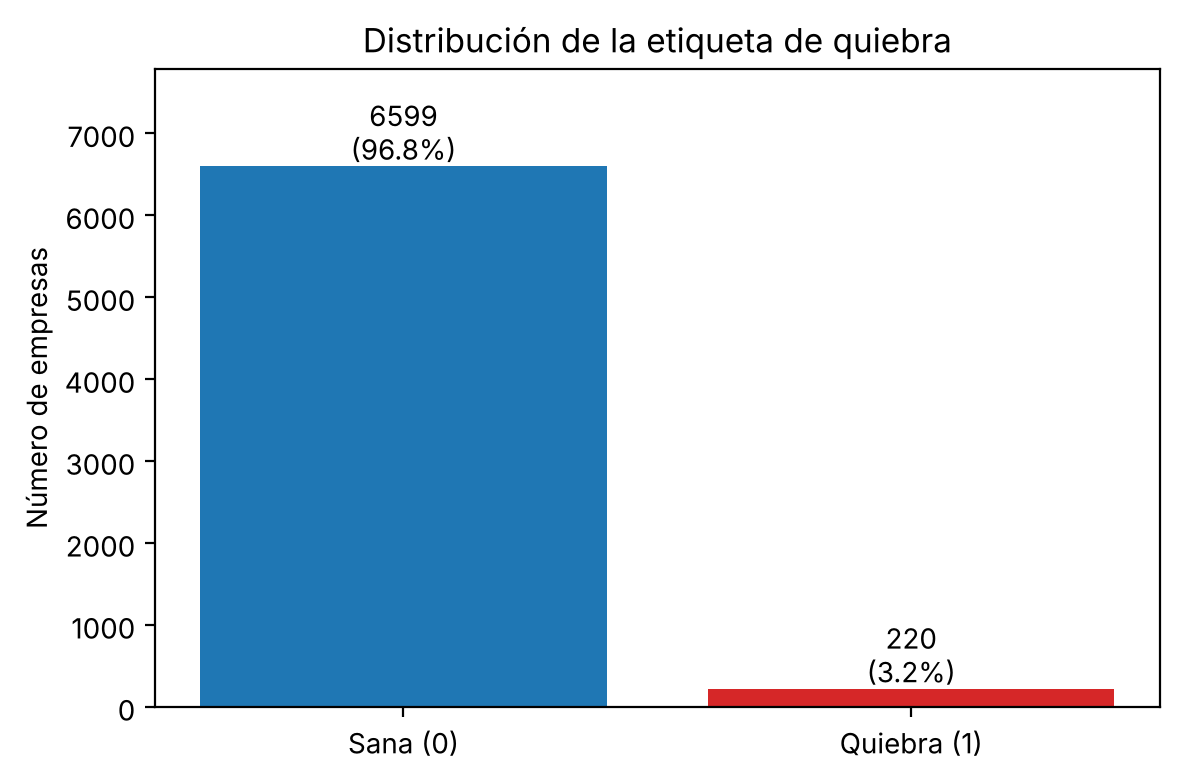

In [6]:
# Gráfica 1: distribución de la etiqueta de quiebra
plt.figure(figsize=(6, 4))
barras = plt.bar(["Sana (0)", "Quiebra (1)"], conteo.values, color=["tab:blue", "tab:red"])
for b, v in zip(barras, conteo.values):
    plt.text(b.get_x() + b.get_width() / 2, v, f"{v}\n({v / conteo.sum():.1%})", ha="center", va="bottom")
plt.ylabel("Número de empresas")
plt.title("Distribución de la etiqueta de quiebra")
plt.ylim(0, conteo.max() * 1.18)
plt.tight_layout()
plt.savefig(carpeta_img / "distribucion_clases.png", dpi=150)
plt.show()

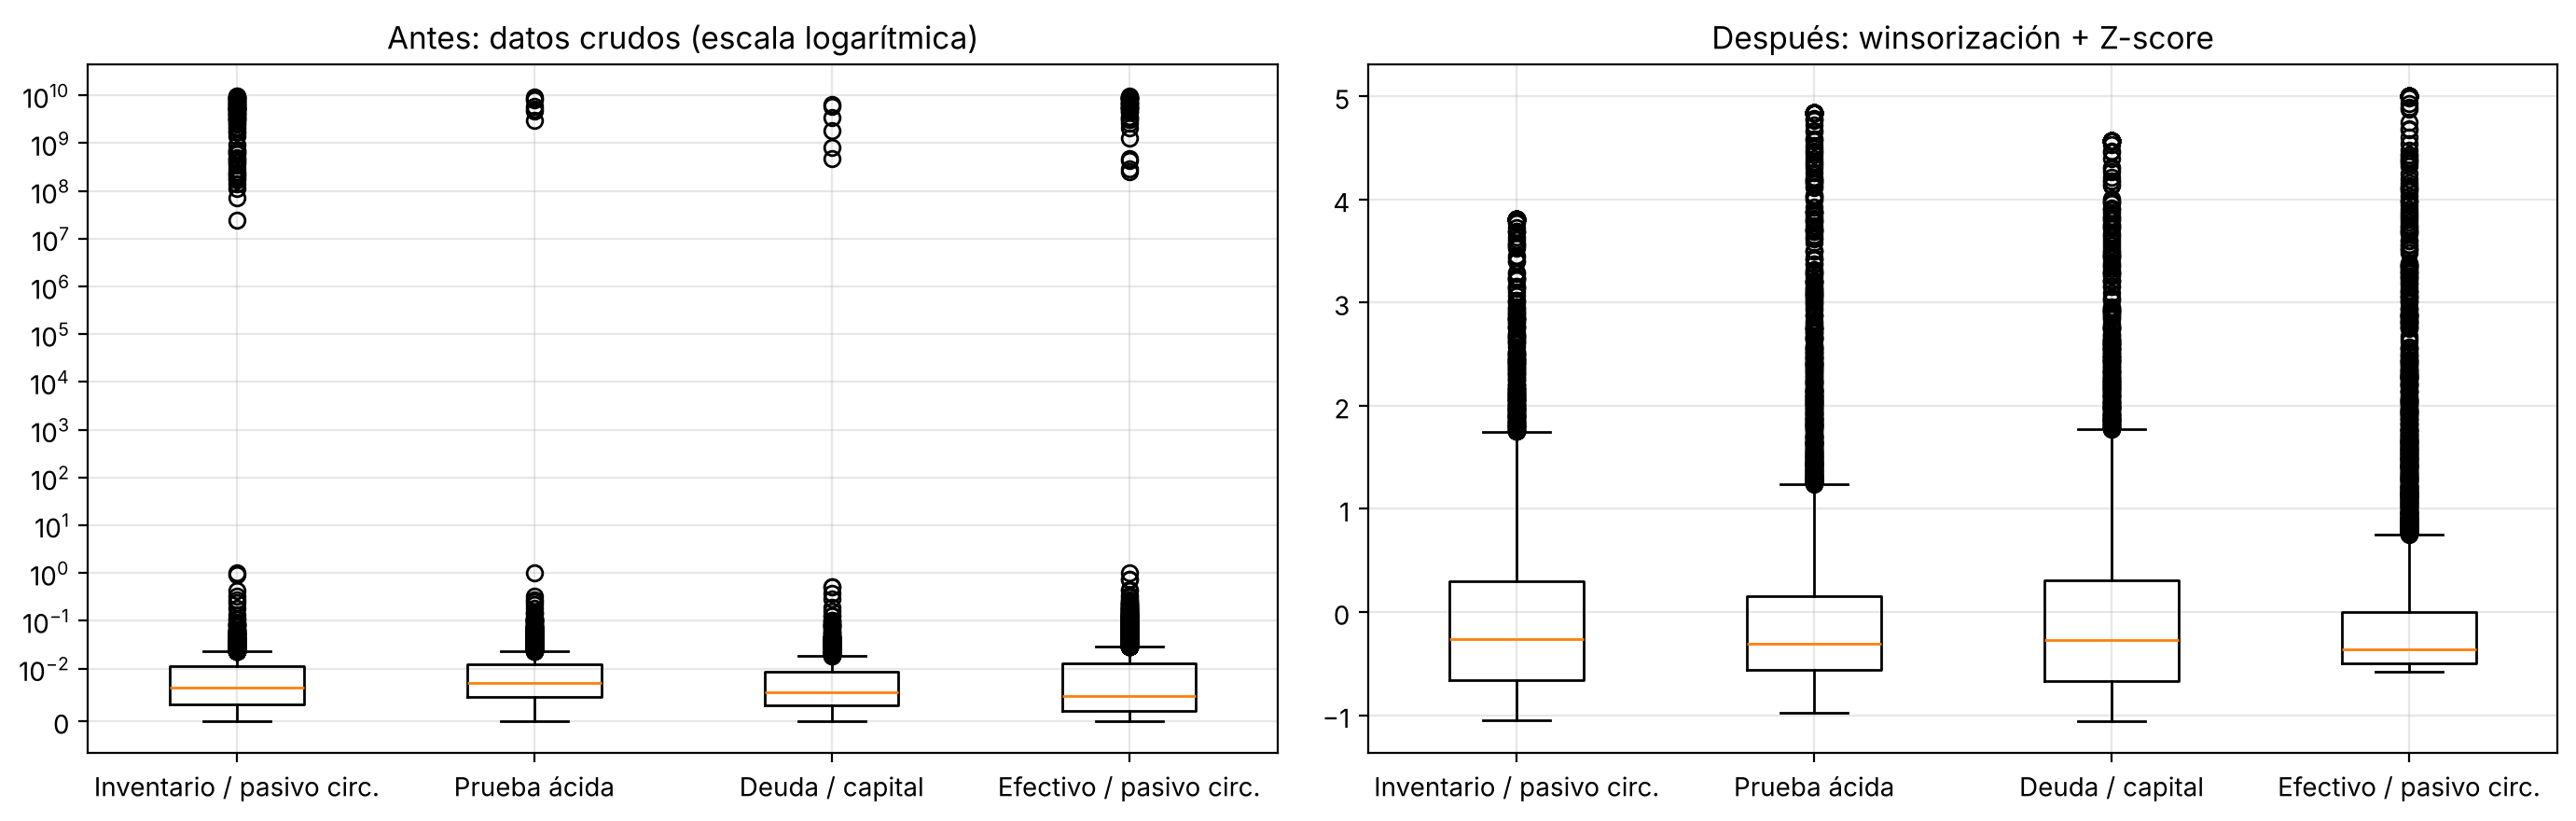

In [7]:
# Gráfica 2: antes y después del tratamiento, en 4 variables con valores extremos
ejemplo = ["Inventory/Current Liability", "Quick Ratio", "Total debt/Total net worth", "Cash/Current Liability"]
nombres_cortos = ["Inventario / pasivo circ.", "Prueba ácida", "Deuda / capital", "Efectivo / pasivo circ."]

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
axs[0].boxplot([entrenamiento[v] for v in ejemplo])
axs[0].set_yscale("symlog", linthresh=1e-2)
axs[0].set_title("Antes: datos crudos (escala logarítmica)")
axs[1].boxplot([entrenamiento_z[v] for v in ejemplo])
axs[1].set_title("Después: winsorización + Z-score")
for ax in axs:
    ax.set_xticks(range(1, len(ejemplo) + 1), nombres_cortos)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(carpeta_img / "antes_despues_tratamiento.png", dpi=150)
plt.show()

In [8]:
# Tabla: rango de esas variables antes y después
comparacion = pd.DataFrame({
    "Máximo crudo": entrenamiento[ejemplo].max(),
    "Mediana cruda": entrenamiento[ejemplo].median(),
    "Mínimo tratado (z)": entrenamiento_z[ejemplo].min(),
    "Máximo tratado (z)": entrenamiento_z[ejemplo].max()})
comparacion.index = nombres_cortos
comparacion.style.format("{:.4g}")

,Máximo crudo,Mediana cruda,Mínimo tratado (z),Máximo tratado (z)
Inventario / pasivo circ.,9.91e+09,0.006454,-1.053,3.808
Prueba ácida,9.23e+09,0.007296,-0.9745,4.839
Deuda / capital,6.47e+09,0.005575,-1.061,4.568
Efectivo / pasivo circ.,9.65e+09,0.004786,-0.5777,5.006


**Análisis del tratamiento**

- **Antes:** en las cuatro variables de ejemplo la mediana es menor a 0.01, pero algunas empresas tienen valores de miles de millones. Esos pocos puntos ocupan casi todo el rango de la gráfica.
- **Después:** con la winsorización los errores quedan en el percentil 99 de los valores válidos y, tras el Z-score, todas las variables quedan centradas en 0 con desviación estándar 1. Ahora las cuatro variables se pueden comparar en la misma escala.
- Ninguna empresa se eliminó: el tratamiento solo ajusta los valores extremos. Se eliminaron 9 variables (8 con escala inconsistente y 1 constante), y quedan **86 razones financieras**, muy por arriba del mínimo de 10.
- En los datos de prueba y en las empresas nuevas los valores pueden quedar un poco fuera del rango del entrenamiento. Es normal, porque se transforman con los parámetros del entrenamiento, igual que pasará con cualquier empresa nueva en la práctica.

In [9]:
# Apoyo para la selección de variables (actividad 4a):
# diferencia de medias normalizadas entre empresas en quiebra y sanas (solo entrenamiento)
medias_clase = entrenamiento_z.groupby(col_objetivo)[variables].mean()
ranking = pd.DataFrame({"diferencia_medias_z": medias_clase.loc[1] - medias_clase.loc[0]})
ranking["diferencia_absoluta"] = ranking["diferencia_medias_z"].abs()
ranking = ranking.sort_values("diferencia_absoluta", ascending=False)
ranking.index.name = "variable"
ranking.head(15).round(3)

,diferencia_medias_z,diferencia_absoluta
variable,,
Net Income to Stockholder's Equity,-1.863,1.863
Borrowing dependency,1.735,1.735
Total debt/Total net worth,1.697,1.697
Net Income to Total Assets,-1.646,1.646
Retained Earnings to Total Assets,-1.576,1.576
Liability to Equity,1.555,1.555
ROA(A) before interest and % after tax,-1.461,1.461
ROA(B) before interest and depreciation after tax,-1.432,1.432
Current Liability to Equity,1.394,1.394


Esta tabla es un **punto de partida para la selección de variables**. Muestra cuánto se separan, en promedio, las empresas en quiebra de las sanas en cada variable, medido en desviaciones estándar. Las de arriba coinciden con la teoría financiera: en las empresas que quiebran la rentabilidad sobre capital y activos es más baja, y el endeudamiento y la dependencia de préstamos son más altos. Varias de estas variables están muy correlacionadas entre sí (por ejemplo, las tres versiones del ROA), así que conviene revisarlo al elegir las variables finales.

<a id="archivos"></a>

## 5. Archivos de datos tratados

In [10]:
# Guardar los archivos tratados
entrenamiento_z.to_csv(carpeta_tratados / "entrenamiento_normalizado.csv", index_label="id_empresa")
prueba_z.to_csv(carpeta_tratados / "prueba_normalizado.csv", index_label="id_empresa")
nuevas_z.to_csv(carpeta_tratados / "empresas_nuevas_normalizado.csv", index_label="id_empresa")
nuevas.to_csv(carpeta_tratados / "empresas_nuevas_original.csv", index_label="id_empresa")

parametros = pd.DataFrame({"percentil_1": p_inf, "percentil_99": p_sup,
                           "media": media, "desviacion_estandar": desviacion})
parametros.index.name = "variable"
parametros.to_csv(carpeta_tratados / "parametros_normalizacion.csv")
ranking.to_csv(carpeta_tratados / "ranking_variables.csv")

for archivo in sorted(carpeta_tratados.glob("*.csv")):
    print(f"{archivo.name:40s} {pd.read_csv(archivo).shape}")

empresas_nuevas_normalizado.csv          (5, 88)
empresas_nuevas_original.csv             (5, 88)
entrenamiento_normalizado.csv            (5451, 88)
parametros_normalizacion.csv             (86, 5)
prueba_normalizado.csv                   (1363, 88)
ranking_variables.csv                    (86, 3)


| Archivo | Contenido |
|---|---|
| `datos/crudos/taiwan_bankruptcy.csv` | Base original descargada de UCI, sin cambios |
| `datos/tratados/entrenamiento_normalizado.csv` | 80 % de las empresas, tratadas y normalizadas: **para entrenar** |
| `datos/tratados/prueba_normalizado.csv` | 20 % de las empresas, tratadas con los parámetros del entrenamiento: **para evaluar** |
| `datos/tratados/empresas_nuevas_normalizado.csv` | Las 5 empresas reservadas para la predicción final (actividad 5) |
| `datos/tratados/empresas_nuevas_original.csv` | Las mismas 5 empresas con sus valores originales (86 variables) |
| `datos/tratados/parametros_normalizacion.csv` | Percentiles, media y desviación de cada variable, para tratar cualquier empresa nueva igual |
| `datos/tratados/ranking_variables.csv` | Diferencia entre empresas en quiebra y sanas por variable (apoyo para la selección) |

**Notas para el resto del equipo**
- Cada archivo trae la columna `id_empresa` (renglón de la base original), las 86 variables normalizadas y la columna `quiebra` (1 = quiebra, 0 = sana).
- Para leerlos: `pd.read_csv("datos/tratados/entrenamiento_normalizado.csv", index_col="id_empresa")`.
- La etiqueta de las empresas nuevas se conoce, pero **no debe usarse para entrenar**: solo sirve para comprobar la predicción final.
- Por el desbalance (3.2 % de quiebras), la exactitud sola no basta: hay que revisar también la precisión y el *recall* de la clase "quiebra" y, si hace falta, balancear el entrenamiento.